# Hybrid baseline vs. 3-class multi-Otsu on hematoxylin, tight box vs. 1 um padded centroid box

**Three rows per click, same 24 clicks as the rest of this family:**
1. **`baseline`** -- the original hybrid, `explore_hybrid_tightening`, copied verbatim: gray and
   hem both cut at Otsu + 0.5 * std(foreground), gray region selected and dilated, hem components
   kept only if fully inside it, solidity gate on single components, parameters in pixels.
2. **`multi-Otsu`** -- hematoxylin only. The 51 px window is split into 3 classes with
   `skimage.filters.threshold_multiotsu` and the top class is kept (roughly: pale background /
   nuclei / condensed chromatin). The top-class mask is then **dilated by 1 px** (3x3 cross, the
   family's `GATE_KERNEL`) before labelling, so pieces 1-2 px apart fuse and every piece regains a
   pixel of rim. Components are picked around the click (rules below). **No gray stage and no
   solidity check.** The box is the selection's bounding box, centred on that
   bounding box -- the same box convention as the baseline.
3. **`multi-Otsu + 1 um pad`** -- the *same selected components* as row 2, but the box adds 1 um
   of margin on every side and is centred on the **centroid of the selected pixels**. The
   baseline and row 2 already centre on the selection's bounding-box centre, so "re-centre on the
   component" here means the pixel centroid; the box is widened as needed so the whole selection
   still sits at least 1 um inside it on every side.

**Parameters for rows 2-3, all in micrometres** (converted per ROI with its own mpp):

| parameter | value | why |
|---|---|---|
| classes | 3, keep the top class | 4 classes is unstable (checked outside this notebook: on `402.tiff`/20254 its top class kept 0.1% of the window) |
| `MO_DILATE_ITERATIONS` | 1 | one pass of the 3x3 cross on the top-class mask, before labelling |
| `MO_MIN_COMPONENT_UM2` | 1.0 um^2 | speck floor, applied after dilation. Within 5 um of the clicks, specks reach 0.86 um^2 and the smallest included piece other than the click's own is 1.15 um^2 (Step 1d; 0.68 / 1.28 um^2 before the dilation was added); about one chromosome cross-section, and the design notes' 15 px |
| `MO_MIN_AREA_UM2` | 3.0 um^2 | the baseline's `MIN_AREA=50` px converted at 0.245 um/px, applied to the selected union |
| `MO_MIN_BASE_UM` | 5.0 um | the baseline's `HEM_MIN_BASE_SIZE_PX=20` converted at 0.25 um/px |
| `MO_CLICK_RADIUS_UM` | **3.75 um, component centre** | see below |

**Why the radius is measured to component centres now.** The multi-Otsu cut is stricter than the
baseline's, so more clicks land on background and go through the fallback union, where the radius
is the only thing keeping neighbours out. Measured to the nearest pixel (the baseline's rule), the
anaphase gap at `013.tiff`/243 needs >= 2.9 um to reach its plates, while neighbour pieces sit at
2.5-2.8 um (`245.tiff`/6317, `245.tiff`/6243, `300.tiff`/14575), so no value works. Measured to
centres, the anaphase plates are at 3.26-3.69 um and the `6317` neighbour at 3.98 um; 3.75 um is
the value in 0.25 um steps that keeps both plates and drops that neighbour. **It is fitted to
these 24 clicks, with margins under 1 px** (Step 1d prints the distances). It does not exclude a
23 px neighbour piece at 3.52 um on `245.tiff`/6243.

**The radius was chosen on the undilated components and kept unchanged when the 1 px dilation was
added.** After dilation the margins are tighter: the big anaphase plate at `013.tiff`/243 sits at
3.69 um and `300.tiff`/14575's second chromatin mass at 3.66 um, 0.06-0.09 um inside; the 14575
neighbour at 4.16 um and 6243's C-shaped neighbour at 4.43 um are outside; the 6243 neighbour
piece (now 2.83 um^2) at 3.50 um is still inside.

**Everything else about the hem step is the baseline's:** the base case takes the component under
the click when its bounding box alone is >= `MO_MIN_BASE_UM`; otherwise the fallback unions every
non-speck component whose centre is within the radius. `connectivity=1` labelling, and the <= 85%
of the window area gate, are unchanged.

**Tripwires:** Steps 1/1b reproduce the family's clicks; Step 3 checks the baseline row against the
committed `hybridhemonlyvsoriginal14_comparison.csv`, that rows 2 and 3 select identical
components, and that row 3's box keeps every selected pixel >= 1 um inside its edge.

In [1]:
import os
import sys

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.filters import threshold_multiotsu
from skimage.measure import label, regionprops
from skimage.color import label2rgb

sys.path.insert(0, '../..')
from midog_utils import channels as ch
from midog_utils import dataset as ds
from midog_utils import evaluate as ev
from midog_utils import find_and_suppress as fs
from midog_utils import seed_selection as ss
from midog_utils import template_match as tm

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 120)

IMAGES_DIR = '../../images/extra_valid'
DB_PATH = '../../databases/MIDOG++.json'
SEED_INDEX = 0                            # same RNG stream as every notebook in this family

# baseline (row 1) -- the original hybrid's own constants, unchanged, in pixels
OTSU_WINDOW = tm.BASE_SIZE                # 51 -- same window tighten_box_otsu reads everywhere else
MIN_AREA, MAX_AREA_FRAC, MIN_SOLIDITY = 50, 0.85, 0.5   # tighten_box_otsu's own defaults
PATCH_SIZE = fs.FSConfig().patch_size     # 73 -- rotation-safe search patch size
BORDER = PATCH_SIZE // 2                  # 36 -- same margin border_filter uses elsewhere
GATE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))  # 3x3 cross; baseline gray-gate dilation, and rows 2-3's 1 px dilation
GATE_ITERATIONS = 1
CLICK_RADIUS_UM = 3.0                     # baseline fallback radius (nearest pixel, um)
HEM_MIN_BASE_SIZE_PX = 20                 # baseline: hem base case must tighten to at least this
DYNAMIC_K = 0.5                           # baseline cut = Otsu + DYNAMIC_K * std(foreground)

# multi-Otsu rows (2-3) -- hematoxylin only, no gray stage, no solidity gate, all in um
MO_CLASSES = 3                            # keep the top of 3 classes
MO_MIN_COMPONENT_UM2 = 1.0                # components smaller than this are specks, never selected
MO_MIN_AREA_UM2 = 3.0                     # the selected union must be at least this (50 px at 0.245 um/px)
MO_MIN_BASE_UM = 5.0                      # base case needs the click's component bbox >= this (20 px at 0.25 um/px)
MO_CLICK_RADIUS_UM = 3.75                 # fallback: component CENTRE within this of the click
PAD_UM = 1.0                              # row 3: margin kept around the selection on every side
MO_DILATE_ITERATIONS = 1                  # dilate the top-class mask this many times with GATE_KERNEL, before labelling

CONTEXT_WINDOW = 91                       # display-only crop size for the spatial-context panel
OUT_PREFIX = 'hybridmultiotsu14'          # distinct from every other notebook's own output files
BASELINE_REFERENCE_CSV = '../hybridhemonlyvsoriginal14_comparison.csv'  # committed baseline boxes (121b023)

print(f'baseline:  original hybrid, px units, radius {CLICK_RADIUS_UM}um (nearest pixel), solidity>={MIN_SOLIDITY}')
print(f'multi-Otsu: {MO_CLASSES} classes, specks<{MO_MIN_COMPONENT_UM2}um^2, union>={MO_MIN_AREA_UM2}um^2, '
      f'base bbox>={MO_MIN_BASE_UM}um, radius {MO_CLICK_RADIUS_UM}um (centre), top class dilated {MO_DILATE_ITERATIONS}px, row 3 pad {PAD_UM}um + centroid')

baseline:  original hybrid, px units, radius 3.0um (nearest pixel), solidity>=0.5
multi-Otsu: 3 classes, specks<1.0um^2, union>=3.0um^2, base bbox>=5.0um, radius 3.75um (centre), top class dilated 1px, row 3 pad 1.0um + centroid


## `explore_hybrid_tightening` / `plot_hybrid_row` -- the baseline, reused unchanged

`explore_hybrid_tightening` is copied verbatim from `hybrid_hem_only_vs_original_14roi.ipynb` cell 3 (itself verbatim from `hybrid_gray_hem_tightening_14roi.ipynb`), and `plot_hybrid_row` verbatim from that notebook's cell 5. Not modified.

In [2]:
def explore_hybrid_tightening(gray_img, hem_img, cx, cy, mpp, otsu_window=OTSU_WINDOW, min_area=MIN_AREA, max_area_frac=MAX_AREA_FRAC, min_solidity=MIN_SOLIDITY, click_radius_um=CLICK_RADIUS_UM, hem_min_base_size_px=HEM_MIN_BASE_SIZE_PX, dynamic_k=DYNAMIC_K):
    '''The original hybrid method, verbatim from hybrid_gray_hem_tightening_14roi.ipynb cell 5:
    connectivity=1 Otsu labeling on both channels, both thresholded at a DYNAMIC cut (Otsu +
    dynamic_k * std of the Otsu-foreground pixels). Gray step: base case takes the one component
    under the click; fallback unions every gray component within click_radius_um. The selected
    region is dilated in ISOLATION. Hem step: base case takes the one component under the click
    only if it alone tightens to >= hem_min_base_size_px; otherwise fallback unions every hem
    component within click_radius_um. Every candidate, either mode, is kept only if COMPLETELY
    inside the dilated gray mask. Returns a dict; see the keys set below.'''
    gray_patch = tm.read_padded_patch(gray_img, cx, cy, otsu_window)
    hem_patch = tm.read_padded_patch(hem_img, cx, cy, otsu_window)
    result = dict(gray_patch=gray_patch, hem_patch=hem_patch, gray_binary=None, gray_otsu_thresh=None,
                  gray_thresh=None, gray_labels=None, gray_mode=None, gray_selected_labels=[],
                  gray_area=None, gray_dilated=None, gray_mask=None, hem_binary=None,
                  hem_otsu_thresh=None, hem_thresh=None, hem_labels=None, hem_center_label=0,
                  hem_mode=None, hem_candidates=[], included_hem_labels=[], union_mask=None,
                  union_area=None, click_radius_px=None, accepted=False,
                  reason='too close to the ROI border to read the Otsu window',
                  bbox=None, base_size=None, center_xy=None)
    if gray_patch is None or hem_patch is None:
        return result

    py, px = gray_patch.shape[0] // 2, gray_patch.shape[1] // 2
    radius_px = ev.radius_px(mpp, click_radius_um)
    result['click_radius_px'] = radius_px
    yy, xx = np.ogrid[:gray_patch.shape[0], :gray_patch.shape[1]]
    near_click = (yy - py) ** 2 + (xx - px) ** 2 <= radius_px ** 2

    gray_u8 = cv2.normalize(gray_patch.astype(np.float32), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    gray_otsu_thresh, _ = cv2.threshold(gray_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    gray_fg_std = float(gray_u8[gray_u8 >= gray_otsu_thresh].std())
    gray_thresh = gray_otsu_thresh + dynamic_k * gray_fg_std
    _, gray_binary = cv2.threshold(gray_u8, gray_thresh, 255, cv2.THRESH_BINARY)
    gray_labels = label(gray_binary, connectivity=1)
    result.update(gray_binary=gray_binary, gray_otsu_thresh=float(gray_otsu_thresh),
                  gray_thresh=float(gray_thresh), gray_labels=gray_labels)

    gray_center_label = int(gray_labels[py, px])
    if gray_center_label != 0:
        gray_mode = 'base (click on gray foreground)'
        gray_selected = [gray_center_label]
    else:
        gray_mode = f'fallback (click on gray background, {click_radius_um:.1f}um = {radius_px:.1f}px search)'
        gray_selected = [int(l) for l in np.unique(gray_labels[near_click]) if l != 0]
    result.update(gray_mode=gray_mode, gray_selected_labels=gray_selected)
    if not gray_selected:
        result['reason'] = f'no gray foreground within {click_radius_um:.1f}um of the click at this Otsu cut'
        return result

    gray_region_mask = np.isin(gray_labels, gray_selected)
    gray_area = int(gray_region_mask.sum())
    result['gray_area'] = gray_area
    if gray_area < min_area:
        result['reason'] = f'gray region area {gray_area}px < min_area {min_area}px'
        return result
    if gray_area > max_area_frac * gray_patch.size:
        result['reason'] = f'gray region area {gray_area}px > {max_area_frac:.0%} of the {gray_patch.size}px window'
        return result
    if len(gray_selected) == 1:
        gray_solidity = next(r.solidity for r in regionprops(gray_labels) if r.label == gray_selected[0])
        if gray_solidity < min_solidity:
            result['reason'] = f'gray component solidity {gray_solidity:.2f} < min_solidity {min_solidity}'
            return result

    component_only = gray_region_mask.astype(np.uint8) * 255
    gray_dilated = cv2.dilate(component_only, GATE_KERNEL, iterations=GATE_ITERATIONS)
    gray_mask = gray_dilated > 0
    result.update(gray_dilated=gray_dilated, gray_mask=gray_mask)

    hem_u8 = cv2.normalize(hem_patch.astype(np.float32), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    hem_otsu_thresh, _ = cv2.threshold(hem_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    hem_fg_std = float(hem_u8[hem_u8 >= hem_otsu_thresh].std())
    hem_thresh = hem_otsu_thresh + dynamic_k * hem_fg_std
    _, hem_binary = cv2.threshold(hem_u8, hem_thresh, 255, cv2.THRESH_BINARY)
    hem_labels = label(hem_binary, connectivity=1)
    result.update(hem_binary=hem_binary, hem_otsu_thresh=float(hem_otsu_thresh),
                  hem_thresh=float(hem_thresh), hem_labels=hem_labels)

    hem_regions = {int(r.label): r for r in regionprops(hem_labels)}
    center_label = int(hem_labels[py, px])
    result['hem_center_label'] = center_label

    region, use_fallback, trigger = None, False, None
    if center_label == 0:
        use_fallback, trigger = True, 'click on hem background'
    else:
        region = hem_regions[center_label]
        hy0, hx0, hy1, hx1 = region.bbox
        candidate_base_size = ss._odd(max(hy1 - hy0, hx1 - hx0), minimum=5)
        if candidate_base_size < hem_min_base_size_px:
            use_fallback = True
            trigger = f"click's hem component alone tightens to {candidate_base_size}px < {hem_min_base_size_px}px"

    if not use_fallback:
        result['hem_mode'] = 'base (click on hem foreground, component large enough alone)'
        result['hem_candidates'] = [center_label]
        if region.area < min_area:
            result['reason'] = f"click's hem component area {region.area}px < min_area {min_area}px"
            return result
        if region.area > max_area_frac * hem_patch.size:
            result['reason'] = f"click's hem component area {region.area}px > {max_area_frac:.0%} of the {hem_patch.size}px window"
            return result
        if region.solidity < min_solidity:
            result['reason'] = f"click's hem component solidity {region.solidity:.2f} < min_solidity {min_solidity}"
            return result
        if not np.all(gray_mask[hem_labels == center_label]):
            result['reason'] = "click's hematoxylin_od component is not completely inside the gray mask"
            return result
        included = [center_label]
    else:
        result['hem_mode'] = f'fallback ({trigger}, {click_radius_um:.1f}um = {radius_px:.1f}px search)'
        candidates = [int(l) for l in np.unique(hem_labels[near_click]) if l != 0]
        result['hem_candidates'] = candidates
        if not candidates:
            result['reason'] = f'no hematoxylin_od foreground within {click_radius_um:.1f}um of the click'
            return result
        included = [l for l in candidates if np.all(gray_mask[hem_labels == l])]
        if not included:
            result['reason'] = f'no hematoxylin_od component within {click_radius_um:.1f}um of the click is completely inside the gray mask'
            return result

    result['included_hem_labels'] = included
    union_mask = np.isin(hem_labels, included)
    ys, xs = np.where(union_mask)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()) + 1, int(xs.min()), int(xs.max()) + 1
    union_area = int(union_mask.sum())
    result.update(union_mask=union_mask, union_area=union_area)
    if union_area < min_area:
        result['reason'] = f'union area {union_area}px < min_area {min_area}px'
        return result
    if union_area > max_area_frac * hem_patch.size:
        result['reason'] = f'union area {union_area}px > {max_area_frac:.0%} of the {hem_patch.size}px window'
        return result

    base_size = ss._odd(max(y1 - y0, x1 - x0), minimum=5)
    half = otsu_window // 2
    ix, iy = int(round(cx)), int(round(cy))
    center_x = ix - half + (x0 + x1 - 1) / 2.0
    center_y = iy - half + (y0 + y1 - 1) / 2.0
    result.update(accepted=True, reason='accepted', bbox=(y0, y1, x0, x1), base_size=int(base_size), center_xy=(center_x, center_y))
    return result


def plot_hybrid_row(axes, row_label, gate_desc, res, rgb, cx, cy, nearby_gt):
    ax_patch, ax_mask, ax_labels, ax_context, ax_template = axes
    ax_patch.text(-0.18, 0.5, row_label, transform=ax_patch.transAxes, rotation=90,
                 va='center', ha='center', fontsize=9, fontweight='bold')

    if res['gray_patch'] is None or res['hem_patch'] is None:
        ax_patch.text(0.5, 0.5, res['reason'], ha='center', va='center', wrap=True, fontsize=9)
        for a in axes:
            a.axis('off')
        return

    py = px = res['gray_patch'].shape[0] // 2

    ax_patch.imshow(res['gray_patch'], cmap='gray')
    ax_patch.plot(px, py, marker='+', color='red', ms=13, mew=2)
    if res['click_radius_px'] is not None:
        ax_patch.add_patch(plt.Circle((px, py), res['click_radius_px'], fill=False, edgecolor='yellow', linestyle='--', linewidth=1.5))
    ax_patch.set_title(f"raw patch (gray_inverted, {res['gray_patch'].shape[0]}px)", fontsize=9)

    ax_mask.imshow(res['gray_binary'], cmap='gray')
    ax_mask.plot(px, py, marker='+', color='red', ms=13, mew=2)
    for lbl in res['gray_selected_labels']:
        ax_mask.contour(res['gray_labels'] == lbl, levels=[0.5], colors='lime', linewidths=2)
    gray_cut_label = f"cut={res['gray_otsu_thresh']:.0f}->{res['gray_thresh']:.0f}/255"
    if res['gray_mask'] is not None:
        ax_mask.contour(res['gray_mask'], levels=[0.5], colors='cyan', linewidths=2, linestyles='dashed')
        ax_mask.set_title(f"gray {gray_cut_label} ({res['gray_mode']})\nselected (lime) -> {gate_desc} (dashed)", fontsize=6.5)
    else:
        ax_mask.set_title(f"gray {gray_cut_label}\nREFUSED: {res['reason']}", fontsize=7, color='firebrick')

    if res['hem_labels'] is None:
        ax_labels.text(0.5, 0.5, f"REFUSED at gray gate:\n{res['reason']}", ha='center', va='center', wrap=True, fontsize=8)
        for a in axes[2:]:
            a.axis('off')
        return

    ax_labels.imshow(label2rgb(res['hem_labels'], bg_label=0))
    ax_labels.plot(px, py, marker='+', color='white', ms=13, mew=2, mec='white')
    ax_labels.contour(res['gray_mask'], levels=[0.5], colors='cyan', linewidths=2, linestyles='dashed')
    if res['hem_mode'] is not None and res['hem_mode'].startswith('fallback'):
        ax_labels.add_patch(plt.Circle((px, py), res['click_radius_px'], fill=False, edgecolor='yellow',
                                       linestyle='--', linewidth=1.5))
    for r in regionprops(res['hem_labels']):
        lbl = int(r.label)
        if lbl in res['included_hem_labels']:
            ax_labels.contour(res['hem_labels'] == lbl, levels=[0.5], colors='lime', linewidths=2)
        elif lbl in res['hem_candidates']:
            ax_labels.contour(res['hem_labels'] == lbl, levels=[0.5], colors='red', linewidths=1)
    mode_label = res['hem_mode'] if res['hem_mode'] is not None else 'n/a'
    verdict = 'ACCEPTED' if res['accepted'] else f"REFUSED: {res['reason']}"
    cut_label = f"cut={res['hem_otsu_thresh']:.0f}->{res['hem_thresh']:.0f}/255" if res['hem_otsu_thresh'] is not None else 'cut=n/a'
    ax_labels.set_title(f"hem vs gray mask, {cut_label} ({mode_label})\nincluded={len(res['included_hem_labels'])}\n{verdict}", fontsize=6.5)

    half_ctx = CONTEXT_WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    h, w = rgb.shape[:2]
    x0n, x1n = ix - half_ctx, ix + half_ctx + 1
    y0n, y1n = iy - half_ctx, iy + half_ctx + 1
    x0c, x1c = max(0, x0n), min(w, x1n)
    y0c, y1c = max(0, y0n), min(h, y1n)
    crop = rgb[y0c:y1c, x0c:x1c]
    ax_context.imshow(crop, extent=(x0c - x0n, x1c - x0n, y1c - y0n, y0c - y0n))
    ax_context.set_xlim(0, x1n - x0n)
    ax_context.set_ylim(y1n - y0n, 0)

    if nearby_gt is not None and len(nearby_gt):
        mitotic_gt = nearby_gt[nearby_gt['category_id'] == ds.MITOTIC]
        other_gt = nearby_gt[nearby_gt['category_id'] != ds.MITOTIC]
        if len(mitotic_gt):
            ax_context.plot(mitotic_gt['cx'].values - x0n, mitotic_gt['cy'].values - y0n, marker='*',
                            color='gold', ms=10, mec='black', mew=0.5, linestyle='None', label='other mitotic GT')
        if len(other_gt):
            ax_context.plot(other_gt['cx'].values - x0n, other_gt['cy'].values - y0n, marker='+',
                            color='silver', ms=8, mew=1.5, linestyle='None', label='non-mitotic GT')

    click_local = (ix - x0n, iy - y0n)
    ax_context.plot(*click_local, marker='x', color='red', ms=11, mew=2, label='click (mitotic)')
    if res['accepted']:
        cxr, cyr = res['center_xy']
        bs = res['base_size']
        icx, icy = int(round(cxr)), int(round(cyr))
        bh = (bs - 1) // 2
        rect = plt.Rectangle((icx - bh - x0n, icy - bh - y0n), bs, bs, fill=False, edgecolor='cyan', linewidth=2)
        ax_context.add_patch(rect)
        ax_context.plot(icx - x0n, icy - y0n, marker='o', color='lime', ms=7, label='template centre')
        ax_context.set_title(f'bbox (base_size={bs}px)', fontsize=9)
    else:
        ax_context.set_title(f"REFUSED\n{res['reason']}", fontsize=8, color='firebrick')
    ax_context.legend(fontsize=5.5, loc='lower right')

    if res['accepted']:
        cxr, cyr = res['center_xy']
        bs = res['base_size']
        tpl = tm.read_padded_patch(rgb, cxr, cyr, bs)
        if tpl is not None:
            ax_template.imshow(tpl)
            ax_template.set_title(f'final template ({bs}x{bs}px)', fontsize=9)
        else:
            ax_template.text(0.5, 0.5, 'template not readable\nat this centre', ha='center', va='center')
    else:
        ax_template.text(0.5, 0.5, 'no template\n(refused)', ha='center', va='center')

    for a in axes:
        a.axis('off')


print('explore_hybrid_tightening / plot_hybrid_row defined (verbatim)')

explore_hybrid_tightening / plot_hybrid_row defined (verbatim)


## `explore_multiotsu_tightening` / `plot_multiotsu_row` -- rows 2 and 3, defined here only

One function serves both rows, so they cannot select different components: row 2 calls it with
`pad_um=0, centre_on='bbox'`, row 3 with `pad_um=PAD_UM, centre_on='centroid'`. Only the box
changes between them.

`plot_multiotsu_row` columns:
1. the raw `hematoxylin_od` patch, click, and the `MO_CLICK_RADIUS_UM` circle (a component is
   eligible in fallback when its **centre** is inside it)
2. the 3-class map (black / gray / white = classes 0 / 1 / 2), before dilation; white is dilated
   by `MO_DILATE_ITERATIONS` px (3x3 cross) and then labelled
3. non-speck components of the dilated mask: **included** thick lime with a lime centre dot; **excluded** thin red
   with a red centre dot (only components whose centre is within 6 um are drawn)
4. the box in spatial context, with the template centre
5. the final template

In [3]:
def explore_multiotsu_tightening(hem_img, cx, cy, mpp, pad_um=0.0, centre_on='bbox', otsu_window=OTSU_WINDOW, classes=MO_CLASSES, min_component_um2=MO_MIN_COMPONENT_UM2, min_area_um2=MO_MIN_AREA_UM2, max_area_frac=MAX_AREA_FRAC, min_base_um=MO_MIN_BASE_UM, click_radius_um=MO_CLICK_RADIUS_UM, dilate_iterations=MO_DILATE_ITERATIONS):
    """
        Hematoxylin-only seed tightening at a multi-Otsu cut, with no gray stage and no solidity gate.
        hem_img (np.ndarray): the full-ROI hematoxylin_od channel.
        cx, cy (float): click position in ROI pixel coordinates.
        mpp (float): this ROI's microns-per-pixel; every um parameter is converted with it.
        pad_um (float): margin kept around the selected pixels on every side, in um (0 = tight bbox).
        centre_on (str): 'bbox' centres the box on the selection's bbox centre, 'centroid' on its pixel centroid.
        dilate_iterations (int): times the top-class mask is dilated with GATE_KERNEL (3x3 cross) before labelling; 0 = none.
        Returns dict: explore_hybrid_tightening's keys plus mo_thresholds, class_map, components, pad_px, centroid_xy.

        Selection: threshold_multiotsu(classes) on the float window, keep the top class, dilate that mask
        dilate_iterations times (so pieces 1-2 px apart can fuse), label it with connectivity=1, drop specks (< min_component_um2). Base case: the component under the click, if
        its bbox's longer side is >= min_base_um. Otherwise fallback: every non-speck component whose
        centroid is within click_radius_um of the click. Gates: union >= min_area_um2 and <= max_area_frac
        of the window. Box: side = odd(longer bbox side) centred on the bbox ('bbox', pad 0 -- the
        baseline's convention), or, for 'centroid', centred on the rounded pixel centroid with a side
        that keeps every selected pixel at least pad_px inside the edge.
    """
    hem_patch = tm.read_padded_patch(hem_img, cx, cy, otsu_window)
    result = dict(hem_patch=hem_patch, mo_thresholds=None, class_map=None, hem_labels=None, components=[],
                  hem_mode=None, hem_candidates=[], included_hem_labels=[], union_mask=None, union_area=None,
                  click_radius_px=None, pad_px=None, centroid_xy=None, accepted=False,
                  reason='too close to the ROI border to read the window', bbox=None, base_size=None, center_xy=None)
    if hem_patch is None:
        return result

    patch = hem_patch.astype(np.float64)
    py, px = patch.shape[0] // 2, patch.shape[1] // 2
    radius_px = click_radius_um / mpp
    pad_px = int(round(pad_um / mpp))
    thresholds = threshold_multiotsu(patch, classes=classes)
    top_class = patch > thresholds[-1]
    if dilate_iterations:
        top_class = cv2.dilate(top_class.astype(np.uint8), GATE_KERNEL, iterations=dilate_iterations) > 0
    hem_labels = label(top_class, connectivity=1)
    result.update(mo_thresholds=[float(t) for t in thresholds], class_map=np.digitize(patch, thresholds),
                  hem_labels=hem_labels, click_radius_px=radius_px, pad_px=pad_px)

    components = []
    for r in regionprops(hem_labels):
        ys, xs = r.coords[:, 0], r.coords[:, 1]
        y0, x0, y1, x1 = r.bbox
        components.append(dict(label=int(r.label), area_um2=r.area * mpp ** 2, centre_um=float(np.hypot(ys.mean() - py, xs.mean() - px)) * mpp,
                               near_um=float(np.hypot(ys - py, xs - px).min()) * mpp, bbox_um=max(y1 - y0, x1 - x0) * mpp,
                               centre_yx=(float(ys.mean()), float(xs.mean())), speck=r.area * mpp ** 2 < min_component_um2))
    result['components'] = components
    by_label = {c['label']: c for c in components}

    click_label = int(hem_labels[py, px])
    if click_label and not by_label[click_label]['speck'] and by_label[click_label]['bbox_um'] >= min_base_um:
        result['hem_mode'] = 'base (click on a component >= MO_MIN_BASE_UM)'
        result['hem_candidates'] = included = [click_label]
    else:
        trigger = 'click on background' if click_label == 0 else ('click on a speck' if by_label[click_label]['speck'] else f"click's component bbox {by_label[click_label]['bbox_um']:.2f}um < {min_base_um}um")
        result['hem_mode'] = f'fallback ({trigger}; centres within {click_radius_um}um)'
        result['hem_candidates'] = included = [c['label'] for c in components if not c['speck'] and c['centre_um'] <= click_radius_um]
    for c in components:
        c['included'] = c['label'] in included
    if not included:
        result['reason'] = f'no non-speck component centre within {click_radius_um}um of the click'
        return result

    result['included_hem_labels'] = included
    union_mask = np.isin(hem_labels, included)
    union_area = int(union_mask.sum())
    result.update(union_mask=union_mask, union_area=union_area)
    if union_area * mpp ** 2 < min_area_um2:
        result['reason'] = f'union area {union_area * mpp ** 2:.2f}um^2 < {min_area_um2}um^2'
        return result
    if union_area > max_area_frac * patch.size:
        result['reason'] = f'union area {union_area}px > {max_area_frac:.0%} of the {patch.size}px window'
        return result

    ys, xs = np.where(union_mask)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()) + 1, int(xs.min()), int(xs.max()) + 1
    half = otsu_window // 2
    ix, iy = int(round(cx)), int(round(cy))
    cy_l, cx_l = float(ys.mean()), float(xs.mean())
    result['centroid_xy'] = (ix - half + cx_l, iy - half + cy_l)
    if centre_on == 'bbox':
        base_size = ss._odd(max(y1 - y0, x1 - x0) + 2 * pad_px, minimum=5)
        center_x, center_y = ix - half + (x0 + x1 - 1) / 2.0, iy - half + (y0 + y1 - 1) / 2.0
    elif centre_on == 'centroid':
        icy, icx = int(round(cy_l)), int(round(cx_l))
        reach = int(max(np.abs(ys - icy).max(), np.abs(xs - icx).max()))
        base_size = 2 * (reach + pad_px) + 1
        center_x, center_y = float(ix - half + icx), float(iy - half + icy)
    else:
        raise ValueError(f"centre_on must be 'bbox' or 'centroid', got {centre_on!r}")
    result.update(accepted=True, reason='accepted', bbox=(y0, y1, x0, x1), base_size=int(base_size), center_xy=(center_x, center_y))
    return result


def plot_multiotsu_row(axes, row_label, res, rgb, cx, cy, nearby_gt):
    """
        Draw one multi-Otsu row: hem patch, 3-class map, components, box in context, final template.
        axes (np.ndarray): the row's five matplotlib axes.
        row_label (str): the label written to the left of the row.
        res (dict): explore_multiotsu_tightening's result.
        rgb (np.ndarray): the full-ROI RGB image.
        cx, cy (float): click position in ROI pixel coordinates.
        nearby_gt (pd.DataFrame): other annotations inside the context crop.
        Returns None: draws into axes.
    """
    ax_patch, ax_classes, ax_labels, ax_context, ax_template = axes
    ax_patch.text(-0.18, 0.5, row_label, transform=ax_patch.transAxes, rotation=90, va='center', ha='center', fontsize=9, fontweight='bold')
    if res['hem_patch'] is None:
        ax_patch.text(0.5, 0.5, res['reason'], ha='center', va='center', wrap=True, fontsize=9)
        for a in axes:
            a.axis('off')
        return

    py = px = res['hem_patch'].shape[0] // 2
    ax_patch.imshow(res['hem_patch'], cmap='gray')
    ax_patch.plot(px, py, marker='+', color='red', ms=13, mew=2)
    ax_patch.add_patch(plt.Circle((px, py), res['click_radius_px'], fill=False, edgecolor='yellow', linestyle='--', linewidth=1.5))
    ax_patch.set_title(f"raw patch (hematoxylin_od, {res['hem_patch'].shape[0]}px)", fontsize=9)

    ax_classes.imshow(res['class_map'], cmap='gray', vmin=0, vmax=MO_CLASSES - 1)
    ax_classes.plot(px, py, marker='+', color='red', ms=13, mew=2)
    kept = float((res['class_map'] == MO_CLASSES - 1).mean())
    ax_classes.set_title(f"{MO_CLASSES}-class multi-Otsu, cuts={', '.join(f'{t:.3f}' for t in res['mo_thresholds'])}\ntop class (white) = {kept:.0%} of the window", fontsize=7)

    ax_labels.imshow(label2rgb(res['hem_labels'], bg_label=0))
    ax_labels.plot(px, py, marker='+', color='white', ms=13, mew=2)
    ax_labels.add_patch(plt.Circle((px, py), res['click_radius_px'], fill=False, edgecolor='yellow', linestyle='--', linewidth=1.5))
    for c in res['components']:
        if c['speck'] or c['centre_um'] > 6.0:
            continue
        colour, width = ('lime', 2) if c.get('included') else ('red', 1)
        ax_labels.contour(res['hem_labels'] == c['label'], levels=[0.5], colors=colour, linewidths=width)
        ax_labels.plot(c['centre_yx'][1], c['centre_yx'][0], marker='o', color=colour, ms=4)
    verdict = 'ACCEPTED' if res['accepted'] else f"REFUSED: {res['reason']}"
    ax_labels.set_title(f"components >= {MO_MIN_COMPONENT_UM2}um^2 after {MO_DILATE_ITERATIONS}px dilation ({res['hem_mode']})\nincluded={len(res['included_hem_labels'])}\n{verdict}", fontsize=6.5)

    half_ctx = CONTEXT_WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    h, w = rgb.shape[:2]
    x0n, x1n = ix - half_ctx, ix + half_ctx + 1
    y0n, y1n = iy - half_ctx, iy + half_ctx + 1
    x0c, x1c = max(0, x0n), min(w, x1n)
    y0c, y1c = max(0, y0n), min(h, y1n)
    ax_context.imshow(rgb[y0c:y1c, x0c:x1c], extent=(x0c - x0n, x1c - x0n, y1c - y0n, y0c - y0n))
    ax_context.set_xlim(0, x1n - x0n)
    ax_context.set_ylim(y1n - y0n, 0)
    if nearby_gt is not None and len(nearby_gt):
        mitotic_gt = nearby_gt[nearby_gt['category_id'] == ds.MITOTIC]
        other_gt = nearby_gt[nearby_gt['category_id'] != ds.MITOTIC]
        if len(mitotic_gt):
            ax_context.plot(mitotic_gt['cx'].values - x0n, mitotic_gt['cy'].values - y0n, marker='*', color='gold', ms=10, mec='black', mew=0.5, linestyle='None', label='other mitotic GT')
        if len(other_gt):
            ax_context.plot(other_gt['cx'].values - x0n, other_gt['cy'].values - y0n, marker='+', color='silver', ms=8, mew=1.5, linestyle='None', label='non-mitotic GT')
    ax_context.plot(ix - x0n, iy - y0n, marker='x', color='red', ms=11, mew=2, label='click (mitotic)')
    if res['accepted']:
        cxr, cyr = res['center_xy']
        bs = res['base_size']
        icx, icy = int(round(cxr)), int(round(cyr))
        bh = (bs - 1) // 2
        ax_context.add_patch(plt.Rectangle((icx - bh - x0n, icy - bh - y0n), bs, bs, fill=False, edgecolor='cyan', linewidth=2))
        ax_context.plot(icx - x0n, icy - y0n, marker='o', color='lime', ms=7, label='template centre')
        ax_context.set_title(f'box (base_size={bs}px)', fontsize=9)
        tpl = tm.read_padded_patch(rgb, cxr, cyr, bs)
        if tpl is not None:
            ax_template.imshow(tpl)
            ax_template.set_title(f'final template ({bs}x{bs}px)', fontsize=9)
        else:
            ax_template.text(0.5, 0.5, 'template not readable\nat this centre', ha='center', va='center')
    else:
        ax_context.set_title(f"REFUSED\n{res['reason']}", fontsize=8, color='firebrick')
        ax_template.text(0.5, 0.5, 'no template\n(refused)', ha='center', va='center')
    ax_context.legend(fontsize=5.5, loc='lower right')
    for a in axes:
        a.axis('off')


print('explore_multiotsu_tightening / plot_multiotsu_row defined')

explore_multiotsu_tightening / plot_multiotsu_row defined


## Step 1 -- reproduce the 14 joint-valid clicks, verified against the precision@K notebook's own run

Copied verbatim from `hybrid_gray_hem_tightening_14roi.ipynb` (which itself copied it from
`production_seed_tightening_detail_14roi.ipynb`) -- same RNG stream, same rejection order, same
`KNOWN_SEED_ANN_ID`/`KNOWN_BASE_SIZE` tripwire snapshot. Guarantees this notebook's first 14
clicks are the *same* 14 clicks the rest of this notebook family uses.

In [4]:
# Snapshot from production_seed_precision_at_k_chromatin_hem_bbox.ipynb's own committed run
# (2026-09-16, Gate 1 confirmed). Verification target for this cell's independent re-derivation.
KNOWN_SEED_ANN_ID = {
    '013.tiff': 249, '094.tiff': 2512, '201.tiff': 4457, '233.tiff': 5761, '245.tiff': 6317,
    '246.tiff': 6548, '300.tiff': 14499, '301.tiff': 14969, '402.tiff': 20254, '403.tiff': 20356,
    '459.tiff': 22441, '460.tiff': 22577, '529.tiff': 24918, '548.tiff': 25804,
}
KNOWN_BASE_SIZE = {  # (hematoxylin_od, gray_inverted)
    '013.tiff': (39, 39), '094.tiff': (23, 25), '201.tiff': (29, 51), '233.tiff': (23, 25),
    '245.tiff': (23, 51), '246.tiff': (27, 41), '300.tiff': (25, 49), '301.tiff': (33, 41),
    '402.tiff': (25, 29), '403.tiff': (31, 51), '459.tiff': (31, 33), '460.tiff': (41, 47),
    '529.tiff': (33, 37), '548.tiff': (27, 29),
}


def draw_joint_valid_seed(fn, image_id, roi_shape, hem, gray_inv, gt):
    '''Reproduces the precision@K notebook's own joint-validity draw: a candidate is accepted
    only if tightened_template_box succeeds under BOTH channels and the resulting centre has a
    readable search patch in hem. Same RNG stream, same rejection order.

    fn (str): the ROI's file name, used only in the raised error.
    image_id (int): seeds the RNG stream ([SEED_INDEX, image_id]).
    roi_shape (tuple): the ROI's array shape, for the border filter.
    hem, gray_inv (np.ndarray): the two channel arrays.
    gt (pd.DataFrame): this ROI's full annotation table.

    Returns tuple[pd.Series, dict, int]: (the accepted row, {'hem_bbox': (base,cx,cy),
    'gray_bbox': (base,cx,cy)}, n_retries).
    '''
    seed_pool, flagged = ss.agreement_pool(gt[gt['category_id'] == ds.MITOTIC])
    seed_pool = ss.border_filter(seed_pool, BORDER, roi_shape)
    rng = np.random.default_rng([SEED_INDEX, image_id])
    working, retries = seed_pool.copy(), 0
    while len(working) > 0:
        idx = int(rng.integers(len(working)))
        row = working.iloc[idx]
        r_hem = ss.tightened_template_box(hem, float(row['cx']), float(row['cy']), otsu_window=OTSU_WINDOW)
        r_gray = ss.tightened_template_box(gray_inv, float(row['cx']), float(row['cy']), otsu_window=OTSU_WINDOW)
        ok = (r_hem is not None and r_gray is not None
              and tm.read_padded_patch(hem, r_hem[1], r_hem[2], PATCH_SIZE) is not None
              and tm.read_padded_patch(hem, r_gray[1], r_gray[2], PATCH_SIZE) is not None)
        if ok:
            return row, dict(hem_bbox=r_hem, gray_bbox=r_gray), retries
        working = working.drop(working.index[idx])
        retries += 1
    raise ValueError(f'{fn}: joint-valid seed pool exhausted')


images, annotations = ds.load_annotations(DB_PATH)
meta_ix = images.set_index('file_name')[['image_id', 'tumor_type']]
files = sorted(f for f in os.listdir(IMAGES_DIR) if f.endswith('.tiff'))
assert len(files) == 14, f'expected 14 ROIs in {IMAGES_DIR}/, found {len(files)}'

seeds = {}
mismatches = []
for fn in files:
    image_id = int(meta_ix.loc[fn, 'image_id'])
    domain = meta_ix.loc[fn, 'tumor_type']
    rgb = ds.load_roi(f'{IMAGES_DIR}/{fn}')
    roi_shape = rgb.shape
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    gray_inv = ch.to_channel(rgb, 'gray_inverted')
    gt = ds.image_annotations(annotations, fn)

    row, r_by_condition, n_retries = draw_joint_valid_seed(fn, image_id, roi_shape, hem, gray_inv, gt)
    ann_id = int(row['ann_id'])
    base_hem, base_gray = r_by_condition['hem_bbox'][0], r_by_condition['gray_bbox'][0]

    if ann_id != KNOWN_SEED_ANN_ID[fn]:
        mismatches.append((fn, 'seed_ann_id', ann_id, KNOWN_SEED_ANN_ID[fn]))
    if (base_hem, base_gray) != KNOWN_BASE_SIZE[fn]:
        mismatches.append((fn, 'base_size', (base_hem, base_gray), KNOWN_BASE_SIZE[fn]))

    seeds[fn] = dict(domain=domain, image_id=image_id, ann_id=ann_id, cx=float(row['cx']),
                     cy=float(row['cy']), n_retries=n_retries, r_by_condition=r_by_condition)

print(f'{len(seeds)}/14 joint-valid seeds drawn')
print(f'mismatches against the precision@K notebook\'s own committed run: {len(mismatches)}')
if mismatches:
    print(mismatches)
assert not mismatches, ('this notebook\'s joint-validity draw diverged from '
                        'production_seed_precision_at_k_chromatin_hem_bbox.ipynb -- see mismatches above')

14/14 joint-valid seeds drawn
mismatches against the precision@K notebook's own committed run: 0


## Step 1b -- add the annotations `tightening_process_hem_vs_gray.ipynb` shows

Copied verbatim from `hybrid_gray_hem_tightening_14roi.ipynb`. Looks up each `(file_name, ann_id)`
pair by `ann_id` and cross-checks against that notebook's own committed
`tightening_process_summary.csv`. 4 of its 14 clicks are already in the Step 1 set and are not
added again -- 10 new clicks, 24 total.

In [5]:
# Snapshot from tightening_process_hem_vs_gray.ipynb's own committed run
# (tightening_process_summary.csv, 2026-09-16).
TIGHTENING_PROCESS_CLICKS = {
    ('300.tiff', 14581): dict(domain='canine cutaneous mast cell tumor', which='#1', gray_accepted=True, gray_base=45, hem_accepted=False, hem_base=None),
    ('300.tiff', 14575): dict(domain='canine cutaneous mast cell tumor', which='#2', gray_accepted=True, gray_base=33, hem_accepted=True, hem_base=19),
    ('201.tiff', 4457): dict(domain='canine lung cancer', which='#1', gray_accepted=True, gray_base=51, hem_accepted=True, hem_base=29),
    ('201.tiff', 4469): dict(domain='canine lung cancer', which='#2', gray_accepted=True, gray_base=51, hem_accepted=True, hem_base=31),
    ('245.tiff', 6274): dict(domain='canine lymphosarcoma', which='#1', gray_accepted=True, gray_base=47, hem_accepted=False, hem_base=None),
    ('245.tiff', 6243): dict(domain='canine lymphosarcoma', which='#2', gray_accepted=True, gray_base=51, hem_accepted=True, hem_base=35),
    ('459.tiff', 22441): dict(domain='canine soft tissue sarcoma', which='#1', gray_accepted=True, gray_base=33, hem_accepted=True, hem_base=31),
    ('459.tiff', 22446): dict(domain='canine soft tissue sarcoma', which='#2', gray_accepted=True, gray_base=41, hem_accepted=True, hem_base=39),
    ('013.tiff', 254): dict(domain='human breast cancer', which='#1', gray_accepted=True, gray_base=31, hem_accepted=False, hem_base=None),
    ('013.tiff', 243): dict(domain='human breast cancer', which='#2', gray_accepted=False, gray_base=None, hem_accepted=False, hem_base=None),
    ('529.tiff', 24918): dict(domain='human melanoma', which='#1', gray_accepted=True, gray_base=37, hem_accepted=True, hem_base=33),
    ('529.tiff', 24937): dict(domain='human melanoma', which='#2', gray_accepted=True, gray_base=41, hem_accepted=True, hem_base=33),
    ('402.tiff', 20254): dict(domain='human neuroendocrine tumor', which='#1', gray_accepted=True, gray_base=29, hem_accepted=True, hem_base=25),
    ('402.tiff', 20258): dict(domain='human neuroendocrine tumor', which='#2', gray_accepted=True, gray_base=51, hem_accepted=True, hem_base=33),
}

CLICKS = [dict(file_name=fn, ann_id=s['ann_id'], cx=s['cx'], cy=s['cy'], domain=s['domain'],
               source='original_14', guaranteed_valid=True)
          for fn, s in seeds.items()]
existing_keys = {(c['file_name'], c['ann_id']) for c in CLICKS}

extra_mismatches = []
for (fn, ann_id), snap in TIGHTENING_PROCESS_CLICKS.items():
    gt_row = ds.image_annotations(annotations, fn)
    gt_row = gt_row[gt_row['ann_id'] == ann_id]
    assert len(gt_row) == 1, f'{fn}/{ann_id}: expected exactly one annotation, found {len(gt_row)}'
    cx, cy = float(gt_row.iloc[0]['cx']), float(gt_row.iloc[0]['cy'])

    rgb = ds.load_roi(f'{IMAGES_DIR}/{fn}')
    hem_chan = ch.to_channel(rgb, 'hematoxylin_od')
    gray_inv = ch.to_channel(rgb, 'gray_inverted')
    r_hem = ss.tightened_template_box(hem_chan, cx, cy, otsu_window=OTSU_WINDOW)
    r_gray = ss.tightened_template_box(gray_inv, cx, cy, otsu_window=OTSU_WINDOW)
    hem_accepted, hem_base = r_hem is not None, (r_hem[0] if r_hem is not None else None)
    gray_accepted, gray_base = r_gray is not None, (r_gray[0] if r_gray is not None else None)

    if (hem_accepted, hem_base) != (snap['hem_accepted'], snap['hem_base']):
        extra_mismatches.append((fn, ann_id, 'hem', (hem_accepted, hem_base), (snap['hem_accepted'], snap['hem_base'])))
    if (gray_accepted, gray_base) != (snap['gray_accepted'], snap['gray_base']):
        extra_mismatches.append((fn, ann_id, 'gray', (gray_accepted, gray_base), (snap['gray_accepted'], snap['gray_base'])))

    if (fn, ann_id) not in existing_keys:
        CLICKS.append(dict(file_name=fn, ann_id=ann_id, cx=cx, cy=cy, domain=snap['domain'],
                           source='tightening_process_hem_vs_gray', guaranteed_valid=False))
        existing_keys.add((fn, ann_id))

print(f'mismatches against tightening_process_hem_vs_gray.ipynb\'s own committed run: {len(extra_mismatches)}')
if extra_mismatches:
    print(extra_mismatches)
assert not extra_mismatches, ('independent lookup-by-ann_id diverged from '
                              'tightening_process_hem_vs_gray.ipynb -- see mismatches above')

n_extra = len(CLICKS) - len(seeds)
print(f'{len(TIGHTENING_PROCESS_CLICKS)} clicks in tightening_process_hem_vs_gray.ipynb, '
     f'{len(TIGHTENING_PROCESS_CLICKS) - n_extra} already in the original 14, '
     f'{n_extra} new -> {len(CLICKS)} total clicks in this run')

pd.DataFrame(CLICKS)[['source', 'domain', 'file_name', 'ann_id', 'guaranteed_valid']].sort_values(['source', 'domain', 'file_name'])

mismatches against tightening_process_hem_vs_gray.ipynb's own committed run: 0
14 clicks in tightening_process_hem_vs_gray.ipynb, 4 already in the original 14, 10 new -> 24 total clicks in this run


,source,domain,file_name,ann_id,guaranteed_valid
6,original_14,canine cutaneous mast cell tumor,300.tiff,14499,True
7,original_14,canine cutaneous mast cell tumor,301.tiff,14969,True
2,original_14,canine lung cancer,201.tiff,4457,True
3,original_14,canine lung cancer,233.tiff,5761,True
4,original_14,canine lymphosarcoma,245.tiff,6317,True
5,original_14,canine lymphosarcoma,246.tiff,6548,True
10,original_14,canine soft tissue sarcoma,459.tiff,22441,True
11,original_14,canine soft tissue sarcoma,460.tiff,22577,True
0,original_14,human breast cancer,013.tiff,249,True
1,original_14,human breast cancer,094.tiff,2512,True


## Step 1c -- cache ROI arrays

Copied verbatim. Loads each ROI once so Steps 2-3 don't reload the same 14 TIFFs.

In [6]:
CLICK_ARRAYS = {}
for click in CLICKS:
    fn = click['file_name']
    if fn not in CLICK_ARRAYS:
        rgb = ds.load_roi(f'{IMAGES_DIR}/{fn}')
        CLICK_ARRAYS[fn] = dict(rgb=rgb, mpp=ds.roi_mpp(f'{IMAGES_DIR}/{fn}'),
                                gray_inv=ch.to_channel(rgb, 'gray_inverted'),
                                hem_chan=ch.to_channel(rgb, 'hematoxylin_od'))
print(f'loaded and cached {len(CLICK_ARRAYS)} ROIs')

loaded and cached 14 ROIs


## Step 1d -- the measurements behind the speck floor and the radius

For every click that goes through the fallback (the only place the radius and the speck floor
act), this lists each multi-Otsu component whose centre lies within 5 um of the click: its area,
its centre distance (the rule used here), its nearest-pixel distance (the baseline's rule), and
whether it was included. Then the speck/piece area gap across all 24 clicks.

In [7]:
evidence, speck_areas, piece_areas = [], [], []
for click in sorted(CLICKS, key=lambda c: (c['domain'], c['file_name'], c['ann_id'])):
    arrs = CLICK_ARRAYS[click['file_name']]
    r = explore_multiotsu_tightening(arrs['hem_chan'], click['cx'], click['cy'], arrs['mpp'])
    near_click = [c for c in r['components'] if c['centre_um'] <= 5.0]
    speck_areas += [c['area_um2'] for c in near_click if c['speck']]
    piece_areas += [c['area_um2'] for c in near_click if c.get('included') and c['label'] != int(r['hem_labels'][25, 25])]
    if r['hem_mode'].startswith('fallback'):
        evidence += [dict(click=f"{click['file_name']}/{click['ann_id']}", area_um2=round(c['area_um2'], 2), centre_um=round(c['centre_um'], 2),
                          nearest_px_um=round(c['near_um'], 2), included=c['included']) for c in near_click if not c['speck']]
print(f'largest speck (< {MO_MIN_COMPONENT_UM2}um^2) with centre within 5um of a click: {max(speck_areas):.2f}um^2')
print(f'smallest included component that is not the one under the click:        {min(piece_areas):.2f}um^2')
pd.DataFrame(evidence).sort_values(['click', 'centre_um']).reset_index(drop=True)

largest speck (< 1.0um^2) with centre within 5um of a click: 0.86um^2
smallest included component that is not the one under the click:        1.15um^2


,click,area_um2,centre_um,nearest_px_um,included
0,013.tiff/243,2.87,3.27,2.73,True
1,013.tiff/243,2.20,3.45,2.58,True
2,013.tiff/243,11.68,3.69,2.53,True
3,013.tiff/254,24.18,1.80,0.51,True
4,245.tiff/6243,8.93,0.74,0.00,True
5,245.tiff/6243,2.83,3.50,2.34,True
6,245.tiff/6243,9.18,4.43,2.68,False
7,245.tiff/6274,10.96,2.46,0.78,True
8,245.tiff/6274,11.76,2.99,1.59,True
9,300.tiff/14575,10.20,0.74,0.00,True


## Step 2 -- the visuals

One figure per click, 24 total, three rows: `baseline` (drawn with the parent's `plot_hybrid_row`,
unchanged), `multi-Otsu`, `multi-Otsu + 1 um pad`. The context panel (column 4) overlays every
other ground-truth annotation in the crop -- gold stars for other mitotic figures, silver `+` for
non-mitotic ones.

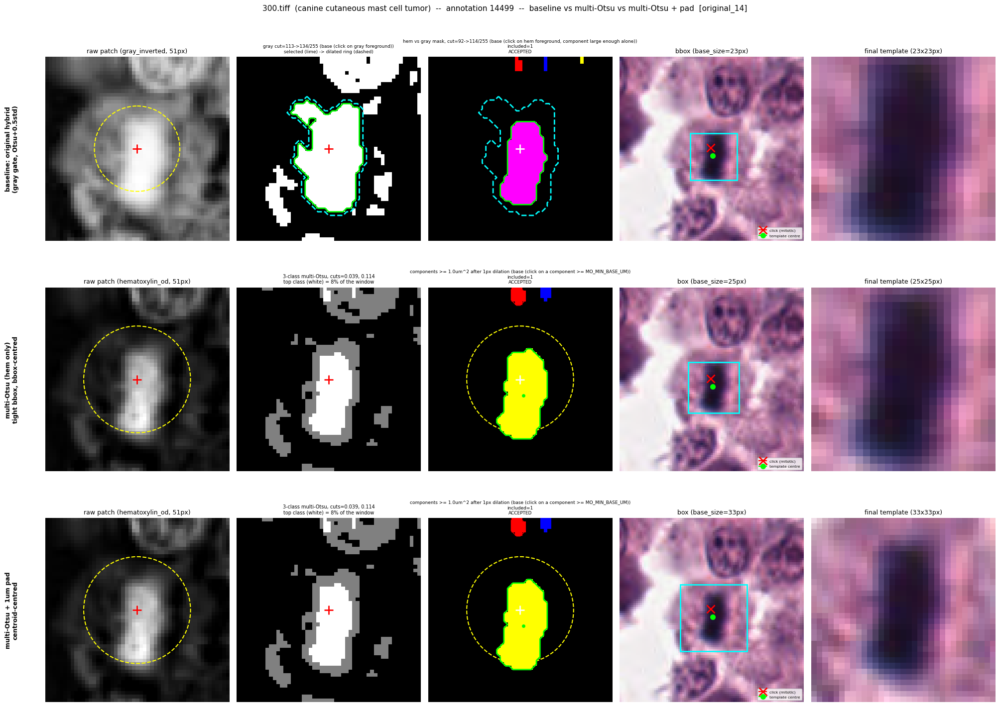

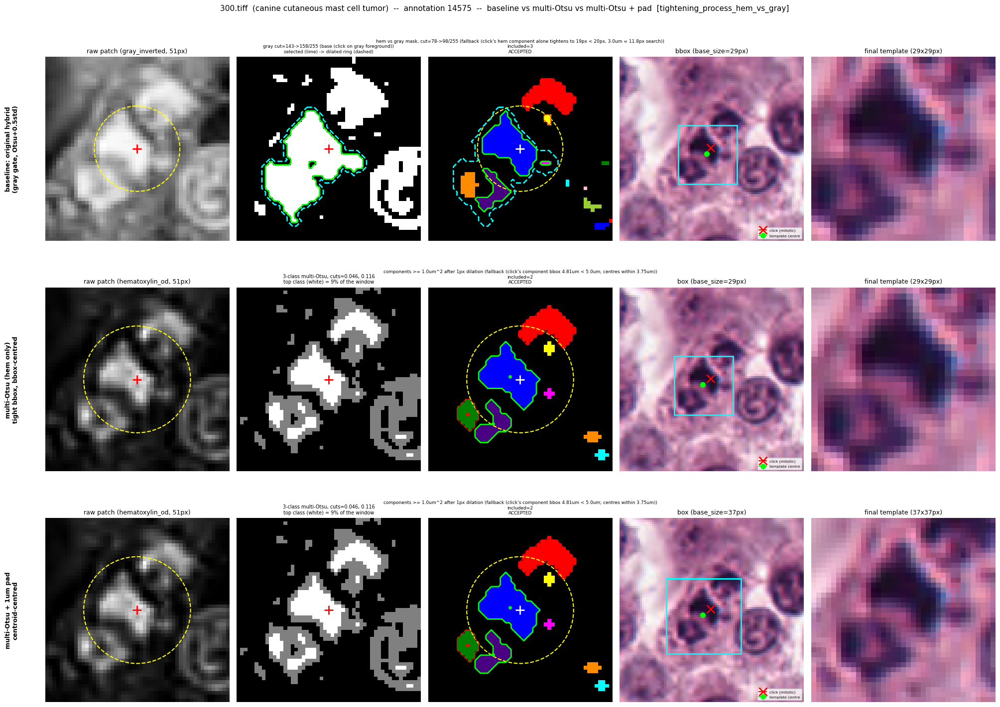

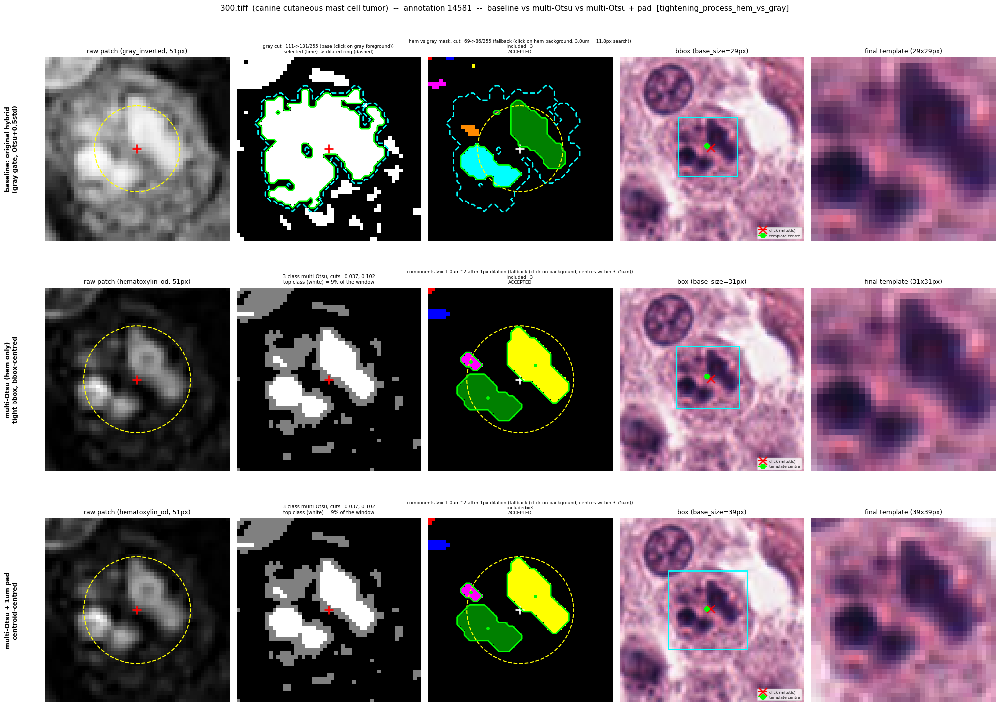

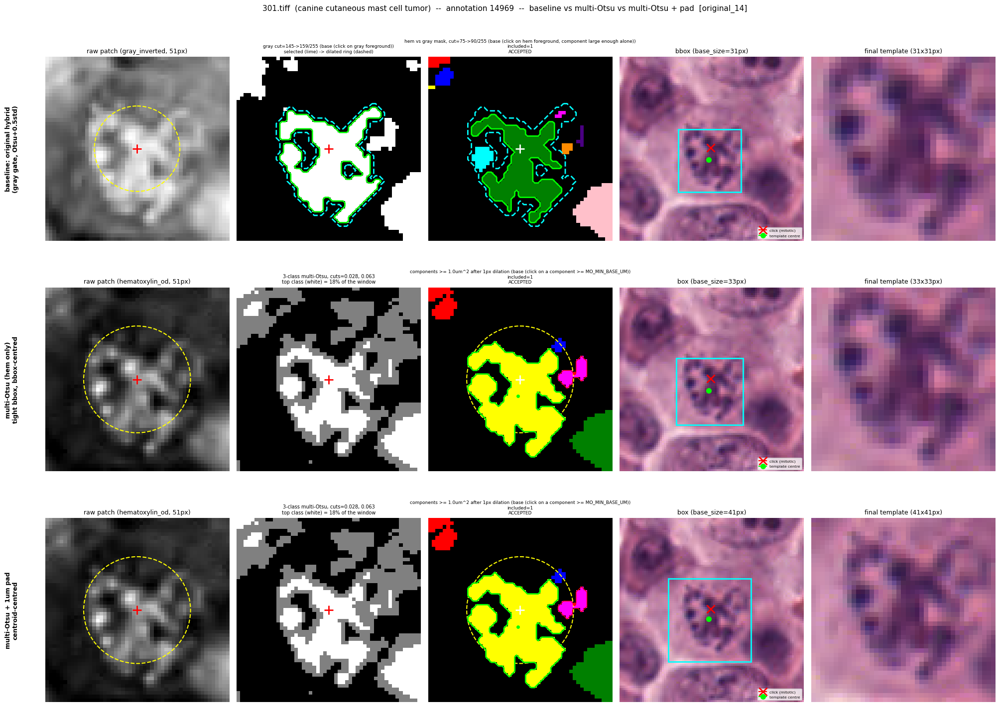

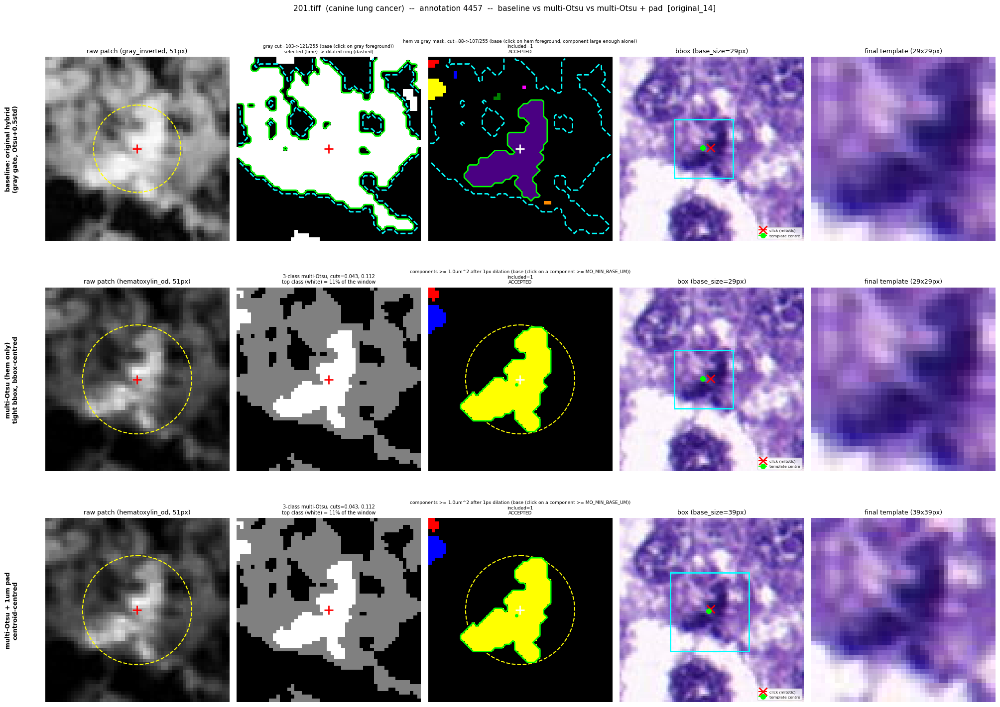

...

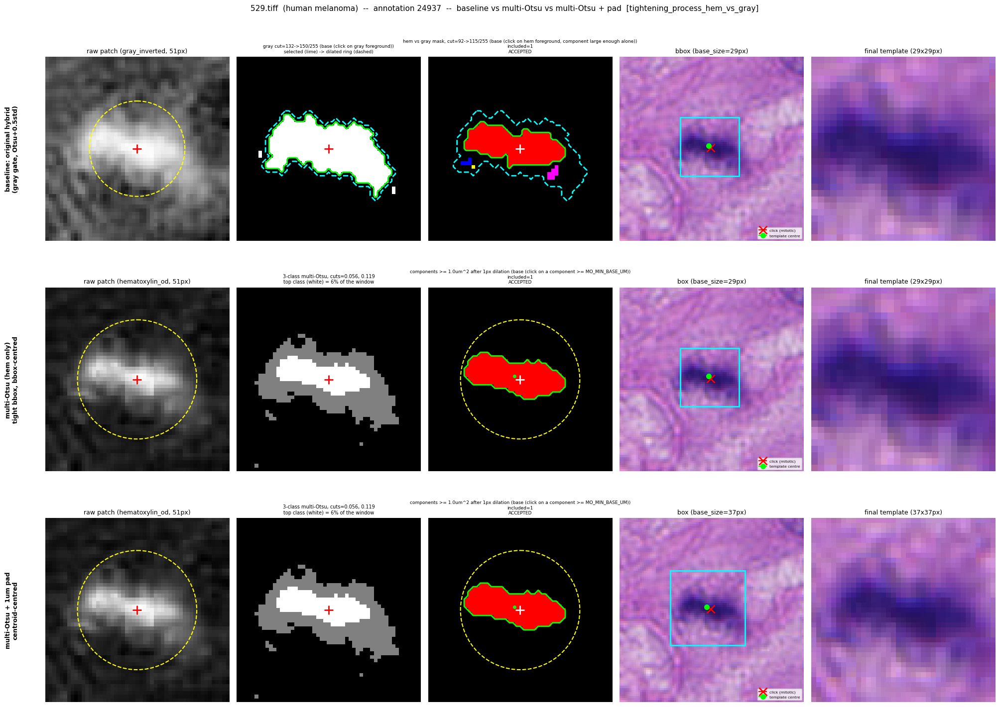

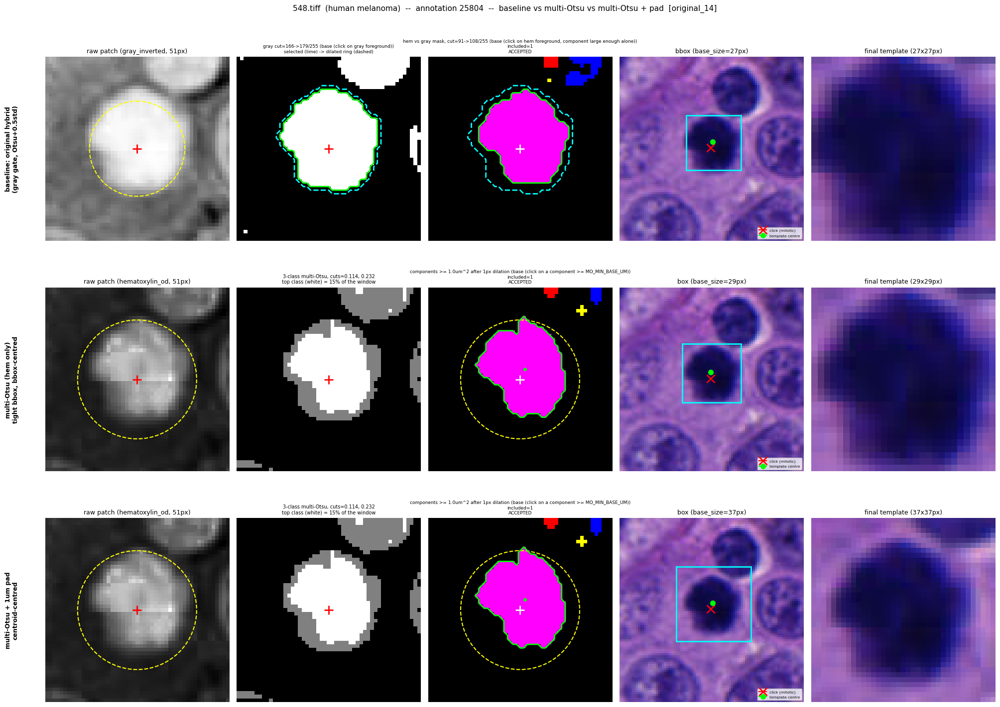

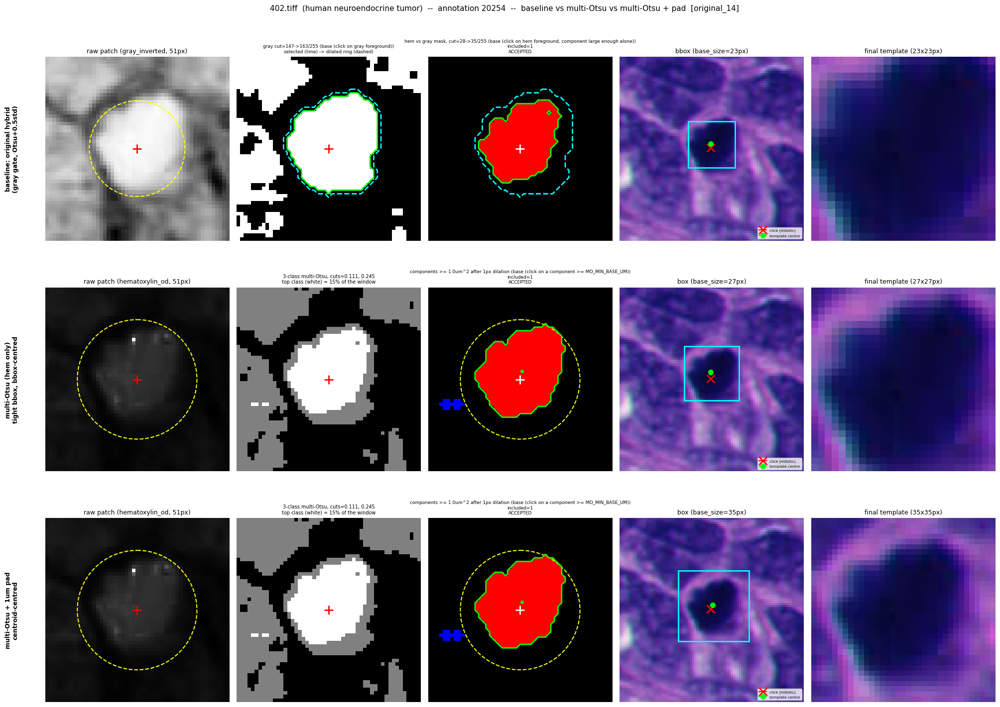

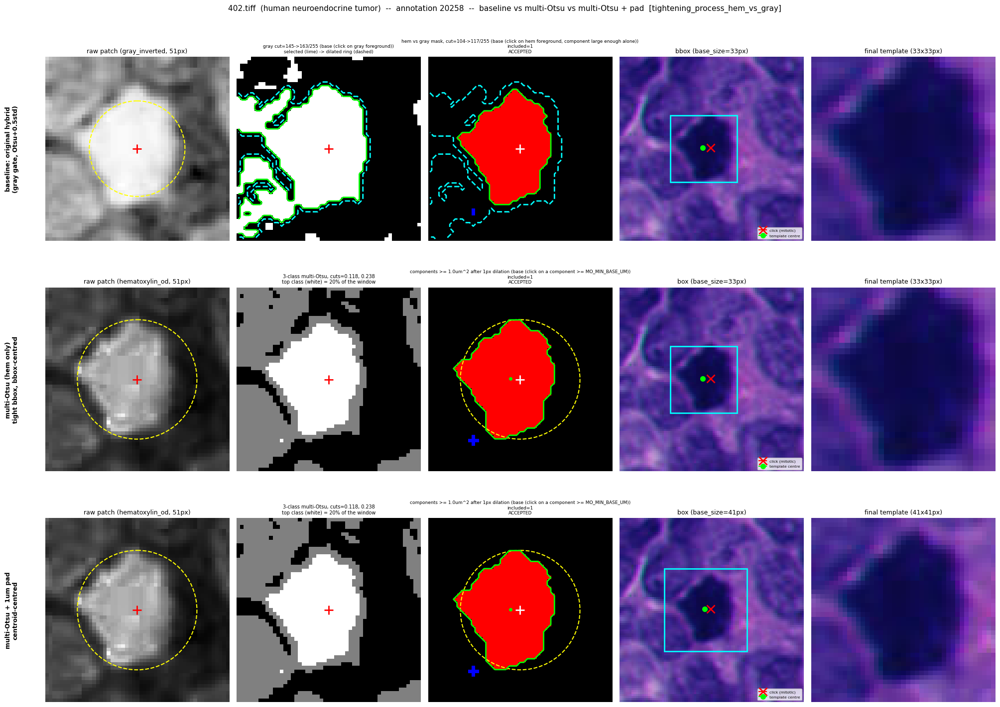

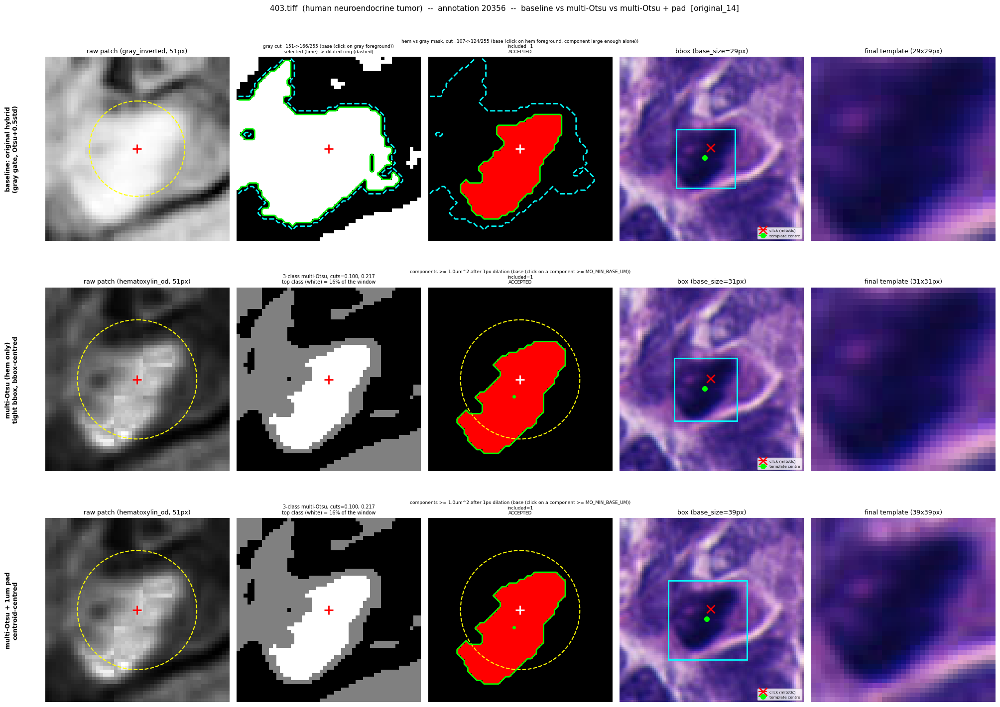

24 clicks rendered


In [8]:
RESULTS = {}

for click in sorted(CLICKS, key=lambda c: (c['domain'], c['file_name'], c['ann_id'])):
    fn, ann_id, cx, cy, domain = click['file_name'], click['ann_id'], click['cx'], click['cy'], click['domain']
    arrs = CLICK_ARRAYS[fn]
    rgb, mpp, gray_inv, hem_chan = arrs['rgb'], arrs['mpp'], arrs['gray_inv'], arrs['hem_chan']

    res = dict(baseline=explore_hybrid_tightening(gray_inv, hem_chan, cx, cy, mpp),
               mo=explore_multiotsu_tightening(hem_chan, cx, cy, mpp),
               mo_pad=explore_multiotsu_tightening(hem_chan, cx, cy, mpp, pad_um=PAD_UM, centre_on='centroid'))
    RESULTS[(fn, ann_id)] = dict(click=click, mpp=mpp, **res)

    half_ctx = CONTEXT_WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    gt_all = ds.image_annotations(annotations, fn)
    dx, dy = gt_all['cx'] - ix, gt_all['cy'] - iy
    nearby_gt = gt_all[(dx.abs() <= half_ctx) & (dy.abs() <= half_ctx) & (gt_all['ann_id'] != ann_id)]

    fig, axes = plt.subplots(3, 5, figsize=(20, 14.4))
    plot_hybrid_row(axes[0], 'baseline: original hybrid\n(gray gate, Otsu+0.5std)', 'dilated ring', res['baseline'], rgb, cx, cy, nearby_gt)
    plot_multiotsu_row(axes[1], 'multi-Otsu (hem only)\ntight bbox, bbox-centred', res['mo'], rgb, cx, cy, nearby_gt)
    plot_multiotsu_row(axes[2], f'multi-Otsu + {PAD_UM:g}um pad\ncentroid-centred', res['mo_pad'], rgb, cx, cy, nearby_gt)
    fig.suptitle(f'{fn}  ({domain})  --  annotation {ann_id}  --  baseline vs multi-Otsu vs multi-Otsu + pad  [{click["source"]}]', fontsize=11, y=1.01)
    fig.tight_layout(h_pad=3.0)
    fig.savefig(f'{OUT_PREFIX}_{fn.replace(".tiff", "")}_{ann_id}.png', dpi=130, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print(f'{len(RESULTS)} clicks rendered')

## Step 3 -- comparison table and tripwires

Sizes are template side lengths in pixels. `centre_shift_px` is how far row 3's centroid centre
moved from row 2's bbox centre. Three tripwires run before the table is trusted:
- the baseline reproduces the committed `hybridhemonlyvsoriginal14_comparison.csv` on all 24 clicks;
- rows 2 and 3 include the identical component set on every click;
- row 3 keeps every selected pixel at least `pad_px` inside its box.

In [9]:
rows = []
padding_failures = []
for (fn, ann_id), r in RESULTS.items():
    b, m, p = r['baseline'], r['mo'], r['mo_pad']
    arrs = CLICK_ARRAYS[fn]
    m0 = explore_multiotsu_tightening(arrs['hem_chan'], r['click']['cx'], r['click']['cy'], r['mpp'], dilate_iterations=0)
    assert m['included_hem_labels'] == p['included_hem_labels'] and m['accepted'] == p['accepted'], (fn, ann_id)
    shift = None
    if p['accepted']:
        ys, xs = np.where(p['union_mask'])
        half = OTSU_WINDOW // 2
        icx = int(round(p['center_xy'][0])) - (int(round(r['click']['cx'])) - half)
        icy = int(round(p['center_xy'][1])) - (int(round(r['click']['cy'])) - half)
        inner = (p['base_size'] - 1) // 2 - p['pad_px']
        if max(np.abs(xs - icx).max(), np.abs(ys - icy).max()) > inner:
            padding_failures.append((fn, ann_id))
        shift = round(float(np.hypot(p['center_xy'][0] - m['center_xy'][0], p['center_xy'][1] - m['center_xy'][1])), 1)
    rows.append(dict(file_name=fn, ann_id=ann_id, source=r['click']['source'], domain=r['click']['domain'], mpp=round(r['mpp'], 4),
                     accepted_baseline=b['accepted'], accepted_mo=m['accepted'],
                     base_baseline=b['base_size'], base_mo_nodilate=m0['base_size'], base_mo=m['base_size'], base_mo_pad=p['base_size'],
                     delta_mo_vs_baseline=None if not (b['accepted'] and m['accepted']) else m['base_size'] - b['base_size'],
                     centre_shift_px=shift, pad_px=p['pad_px'],
                     mode_baseline='base' if (b['hem_mode'] or '').startswith('base') else 'fallback', mode_mo='base' if (m['hem_mode'] or '').startswith('base') else 'fallback',
                     n_included_baseline=len(b['included_hem_labels']), n_included_mo_nodilate=len(m0['included_hem_labels']), n_included_mo=len(m['included_hem_labels']),
                     mode_mo_nodilate='base' if (m0['hem_mode'] or '').startswith('base') else 'fallback',
                     union_um2_mo=None if m['union_area'] is None else round(m['union_area'] * r['mpp'] ** 2, 2),
                     top_class_frac=round(float((m['class_map'] == MO_CLASSES - 1).mean()), 3),
                     reason_mo=None if m['accepted'] else m['reason']))
COMPARISON = pd.DataFrame(rows).set_index(['file_name', 'ann_id']).sort_values('base_baseline')

reference = pd.read_csv(BASELINE_REFERENCE_CSV).set_index(['file_name', 'ann_id'])
baseline_mismatches = [key for key, ref in reference.iterrows()
                       if (bool(COMPARISON.loc[key, 'accepted_baseline']), COMPARISON.loc[key, 'base_baseline']) != (bool(ref['accepted_original']), ref['base_original'])]
print(f'baseline vs committed {BASELINE_REFERENCE_CSV}: {len(reference)} clicks, {len(baseline_mismatches)} mismatches')
assert len(reference) == len(COMPARISON) and not baseline_mismatches, baseline_mismatches
print('rows 2 and 3 include identical components on every click: yes (asserted per click)')
n_accepted_mo = int(COMPARISON['accepted_mo'].sum())
print(f'row 3 keeps every selected pixel >= pad_px inside its box: {n_accepted_mo - len(padding_failures)}/{n_accepted_mo} accepted clicks')
assert not padding_failures, padding_failures

COMPARISON.to_csv(f'{OUT_PREFIX}_comparison.csv')
print(f'-> {OUT_PREFIX}_comparison.csv  ({len(COMPARISON)} rows)')
print()
both = COMPARISON[COMPARISON['accepted_baseline'] & COMPARISON['accepted_mo']]
print(f"accepted: baseline {int(COMPARISON['accepted_baseline'].sum())}/24, multi-Otsu {int(COMPARISON['accepted_mo'].sum())}/24 (row 3 selects the same components, so the same)")
print(f"clicks in fallback mode: baseline {int((COMPARISON['mode_baseline'] == 'fallback').sum())}/24, multi-Otsu {int((COMPARISON['mode_mo'] == 'fallback').sum())}/24")
print(f"multi-Otsu box vs baseline (both accepted, n={len(both)}): same {int((both['delta_mo_vs_baseline'] == 0).sum())}, "
      f"smaller {int((both['delta_mo_vs_baseline'] < 0).sum())}, larger {int((both['delta_mo_vs_baseline'] > 0).sum())}; "
      f"median delta {both['delta_mo_vs_baseline'].median():+.0f}px")
d = both['base_mo'] - both['base_mo_nodilate']
print(f"dilation effect on row 2 (vs the same method undilated): same {int((d == 0).sum())}, larger {int((d > 0).sum())}, smaller {int((d < 0).sum())}; values {d.value_counts().sort_index().to_dict()}")
print(f"clicks in fallback mode undilated: {int((COMPARISON['mode_mo_nodilate'] == 'fallback').sum())}/24")
print(f"row 3 minus row 2 box: median {(both['base_mo_pad'] - both['base_mo']).median():+.0f}px, range {(both['base_mo_pad'] - both['base_mo']).min():+.0f} to {(both['base_mo_pad'] - both['base_mo']).max():+.0f}px")
print(f"row 3 centroid centre vs row 2 bbox centre: median {both['centre_shift_px'].median():.1f}px, max {both['centre_shift_px'].max():.1f}px")
COMPARISON[['domain', 'base_baseline', 'base_mo_nodilate', 'base_mo', 'base_mo_pad', 'delta_mo_vs_baseline', 'centre_shift_px', 'mode_baseline', 'mode_mo_nodilate', 'mode_mo', 'n_included_baseline', 'n_included_mo_nodilate', 'n_included_mo', 'union_um2_mo', 'top_class_frac', 'reason_mo']]

baseline vs committed hybridhemonlyvsoriginal14_comparison.csv: 24 clicks, 0 mismatches
rows 2 and 3 include identical components on every click: yes (asserted per click)
row 3 keeps every selected pixel >= pad_px inside its box: 24/24 accepted clicks
-> hybridmultiotsu14_comparison.csv  (24 rows)

accepted: baseline 24/24, multi-Otsu 24/24 (row 3 selects the same components, so the same)
clicks in fallback mode: baseline 6/24, multi-Otsu 7/24
multi-Otsu box vs baseline (both accepted, n=24): same 10, smaller 4, larger 10; median delta +0px
dilation effect on row 2 (vs the same method undilated): same 1, larger 23, smaller 0; values {0: 1, 2: 21, 6: 1, 12: 1}
clicks in fallback mode undilated: 12/24
row 3 minus row 2 box: median +9px, range +8 to +16px
row 3 centroid centre vs row 2 bbox centre: median 1.1px, max 4.5px


,,domain,base_baseline,base_mo_nodilate,base_mo,base_mo_pad,delta_mo_vs_baseline,centre_shift_px,mode_baseline,mode_mo_nodilate,mode_mo,n_included_baseline,n_included_mo_nodilate,n_included_mo,union_um2_mo,top_class_frac,reason_mo
file_name,ann_id,,,,,,,,,,,,,,,,
245.tiff,6317,canine lymphosarcoma,21,19,21,31,0,1.1,base,fallback,base,1,1,1,14.53,0.236,None
300.tiff,14499,canine cutaneous mast cell tumor,23,23,25,33,2,0.5,base,base,base,1,1,1,16.23,0.079,None
402.tiff,20254,human neuroendocrine tumor,23,25,27,35,4,1.1,base,base,base,1,1,1,22.84,0.146,None
094.tiff,2512,human breast cancer,23,21,23,33,0,1.1,base,fallback,base,1,1,1,16.69,0.103,None
233.tiff,5761,canine lung cancer,23,23,25,33,2,0.7,base,base,base,1,1,1,24.82,0.134,None
246.tiff,6548,canine lymphosarcoma,25,25,27,35,2,0.5,base,base,base,1,1,1,17.43,0.100,None
548.tiff,25804,human melanoma,27,27,29,37,2,1.1,base,base,base,1,1,1,23.18,0.147,None
529.tiff,24937,human melanoma,29,27,29,37,0,0.5,base,base,base,1,1,1,11.63,0.064,None
013.tiff,254,human breast cancer,29,29,31,43,2,2.8,fallback,fallback,fallback,1,1,1,24.18,0.144,None


## Closing notes

**Run with the 1 px dilation.** Rows 2 and 3 dilate the multi-Otsu top class once (3x3 cross)
before labelling. Nothing else changed from the previous run; that run's numbers are given here as
"undilated", and the Step 3 table recomputes them live (`base_mo_nodilate`).

**All three rows accept all 24 clicks. Every tripwire passes:**
- the baseline reproduces the committed boxes 24/24;
- rows 2 and 3 select identical components;
- row 3 keeps every selected pixel at least 1 um inside its box.

**What the dilation did to row 2:**
- **Box size:** +2 px (one pixel of rim a side) on 21 clicks. +6 px at `301.tiff`/14969, where the
  ragged figure fused into one component. +12 px at `300.tiff`/14575. Unchanged at
  `013.tiff`/249, where three pieces fused into one.
- **Fallback:** falls from 12/24 to 7/24 (baseline 6/24). Filling holes inside the figure puts
  the click back on foreground at 6317, 2512, 24918, 22446 and 249.
- **Against the baseline:** same box on 10 clicks, smaller on 4, larger on 10. The median change
  is now 0 px, where the undilated version was -2 px.

**The contested clicks:**
- **`300.tiff`/14575: 29 px, the baseline's box.** The lower-left second chromatin mass fuses into
  one 3.66 um^2 component centred 3.66 um from the click, so it is included. The neighbour at
  4.16 um stays out. The user confirmed (2026-09-29) that this lower-left mass is part of the
  mitotic figure, so the undilated 17 px box was a partial box and this one is right. It gets
  there without the gray stage, but only by 0.09 um (0.36 px).
- **`245.tiff`/6243: 29 px** (baseline 31). The C-shaped neighbour is excluded, but the neighbour
  piece at 3.50 um is still included. This is still a smaller merge; erosion-first's 19 px remains
  the only clean box.
- **`245.tiff`/6317: 21 px, base case**, the baseline's box. No neighbour.
- **Anaphase clicks:** `013.tiff`/243 is 41 px across both plates (the baseline's box), with the
  big plate 0.06 um inside the radius. `245.tiff`/6274 is 35 px.

**Merge count across the family:**

| arm | merges |
|---|---|
| baseline | 1 (6243, 31 px) |
| multi-Otsu + dilation | 1 (6243, 29 px) |
| erosion-first | 0 |

No arm now leaves a partial figure.

**Row 3 (1 um pad, centroid-centred):**
- It is 8-16 px larger than row 2, median +9 px.
- Lopsided selections still stretch it: 6243 is 43 px and 013/243 is 57 px.
- The centroid sits a median 1.1 px from the bbox centre, at most 4.5 px.

**Limits:**
- The radius is fitted to these 24 clicks, and its margins on 14575 and 013/243 are now under
  0.1 um.
- The dilation lets a 0.45 um^2 speck grow past the 1 um^2 floor at `300.tiff`/14581. It is
  included but does not widen that box.
- Geometry only; nothing here has run through precision@K.
